# 05 · Initial Evaluation and Model Selection

**Round 1 demo:** compare the five models, inspect errors and feature importance, evaluate the initial HMM/Viterbi decoder, and show a real interactive route. The student-test partition is used only for development metrics; it is not used to select the model.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
ROOT=Path.cwd()
if not (ROOT/"src").exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/"src"))
DATA=ROOT/"data"/"Student folder"
print("Project:",ROOT,"| dataset found:",DATA.exists())

Project: /Users/yashas/Documents/Codex/2026-11-18/referenced-chatgpt-conversation-this-is-an-2/ML_hackathon | dataset found: True


## Step 1 — Rank models by the training-trip validation score

In [2]:
import pandas as pd,numpy as np,joblib,json,time
from pathsnap.data import read_trip
from pathsnap.matcher import generate_candidates,predict_batch,viterbi_decode
from pathsnap.visualize import create_map
comparison=pd.read_csv(ROOT/"outputs"/"model_comparison.csv")
learned=comparison[comparison.model!="Nearest road segment"].sort_values("validation_top1_accuracy",ascending=False).reset_index(drop=True)
display(learned[["model","validation_top1_accuracy","validation_candidate_macro_f1","validation_candidate_log_loss","student_test_top1_accuracy","student_test_candidate_macro_f1","student_test_candidate_log_loss","student_test_inference_seconds"]].round(4))
selected=learned.iloc[0]
print("Provisional choice:",selected.model,"| validation Top-1:",round(selected.validation_top1_accuracy,4))

,model,validation_top1_accuracy,validation_candidate_macro_f1,validation_candidate_log_loss,student_test_top1_accuracy,student_test_candidate_macro_f1,student_test_candidate_log_loss,student_test_inference_seconds
0,Hist Gradient Boosting,0.7145,0.8478,0.1134,0.7545,0.8609,0.1065,0.1176
1,Random Forest,0.7109,0.8323,0.1451,0.7514,0.8414,0.1385,0.1887
2,Decision Tree,0.6887,0.7989,0.2398,0.7294,0.8024,0.2230,0.0074
3,KNN,0.6079,0.6965,0.5694,0.6569,0.7251,0.5413,0.4895
4,Logistic Regression,0.5522,0.6301,0.4178,0.5650,0.6022,0.4722,0.0048


Provisional choice: Hist Gradient Boosting | validation Top-1: 0.7145


## Step 2 — Quantify the model-choice margin and candidate ceiling

In [3]:
rf=learned[learned.model=="Random Forest"].iloc[0]
print({"selected_model":selected.model,"validation_top1":float(selected.validation_top1_accuracy),"random_forest_validation_top1":float(rf.validation_top1_accuracy),"margin_percentage_points":float(100*(selected.validation_top1_accuracy-rf.validation_top1_accuracy)),"student_candidate_miss_rate":float(selected.student_test_candidate_miss_rate),"selected_student_test_top1":float(selected.student_test_top1_accuracy),"selected_inference_seconds":float(selected.student_test_inference_seconds)})

{'selected_model': 'Hist Gradient Boosting', 'validation_top1': 0.7144956918398379, 'random_forest_validation_top1': 0.7108717688798784, 'margin_percentage_points': 0.36239229599595024, 'student_candidate_miss_rate': 0.063517745302714, 'selected_student_test_top1': 0.7544885177453027, 'selected_inference_seconds': 0.11763608399996883}


The margin is small, so Hist Gradient Boosting is a **provisional phase-1 choice**, not a final claim. It led validation and the student-test development comparison and ran faster than Random Forest in this timing run. Final selection should add group-aware cross-validation, parameter tuning, and repeated timing.

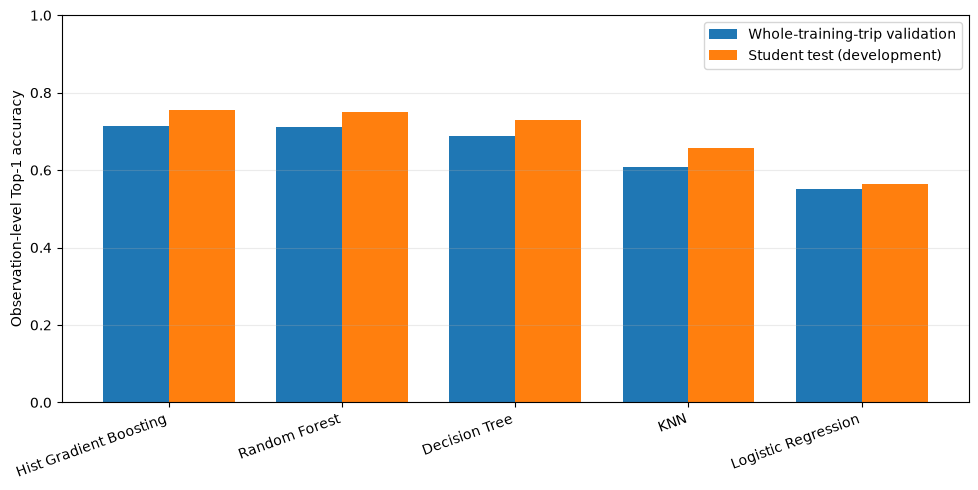

In [4]:
import matplotlib.pyplot as plt
plot_df=pd.concat([comparison[comparison.model=="Nearest road segment"],learned],ignore_index=True)
names=plot_df.model.tolist();x=np.arange(len(names));w=.38
fig,ax=plt.subplots(figsize=(10,5))
ax.bar(x-w/2,plot_df.validation_top1_accuracy,width=w,label="Whole-training-trip validation")
ax.bar(x+w/2,plot_df.student_test_top1_accuracy,width=w,label="Student test (development)")
ax.set_xticks(x,names,rotation=20,ha="right");ax.set_ylim(0,1);ax.set_ylabel("Observation-level Top-1 accuracy");ax.grid(axis="y",alpha=.25);ax.legend();fig.tight_layout()

## Step 3 — Review feature importance and candidate miss rate

In [5]:
importance=pd.read_csv(ROOT/"outputs"/"feature_importance.csv")
display(importance)
print("Candidate miss rate (same generator for each model):",round(100*float(selected.student_test_candidate_miss_rate),2),"%")

,feature,mean_f1_drop,std
0,along_segment_fraction,0.197717,0.005954
1,distance_m,0.194418,0.004242
2,heading_difference_rad,0.116648,0.004348
3,gps_speed_mps,0.007002,0.001442
4,segment_length_m,0.005440,0.002122


Candidate miss rate (same generator for each model): 6.35 %


Permutation importance is computed on the held-out training trips. A candidate miss is a candidate-generation failure, not a classifier failure; it is the practical ceiling for the ranker with the current 12-candidate generator.

## Step 4 — Evaluate classifier-only versus HMM/Viterbi routes

In [6]:
bundle=joblib.load(ROOT/"outputs"/"phase1_model.joblib")
def direct_continuity(ids,arcs):
  return float(np.mean(arcs[ids[:-1],1]==arcs[ids[1:],0])) if len(ids)>1 else 0.0
route_rows=[];selected_trip=None;selected_batch=None;selected_decoded=None
for folder in sorted((DATA/"student_test").iterdir()):
  if not folder.is_dir() or not (folder/f"{folder.name}.track").exists():continue
  trip=read_trip(folder,"student_test");batch=generate_candidates(trip,k=bundle["candidate_k"])
  classifier,prob=predict_batch(bundle["model"],batch);gaps=np.diff(trip.track[:,2],prepend=trip.track[0,2])
  decoded=viterbi_decode(batch.ids,prob,trip.arcs,gaps);valid=batch.truth>=0
  route_rows.append({"trip_id":trip.trip_id,"observations":int(valid.sum()),"candidate_miss_rate":float(batch.candidate_miss[valid].mean()),"classifier_top1":float(np.mean(classifier[valid]==batch.truth[valid])),"viterbi_top1":float(np.mean(decoded[valid]==batch.truth[valid])),"classifier_direct_continuity":direct_continuity(classifier,trip.arcs),"viterbi_direct_continuity":direct_continuity(decoded,trip.arcs)})
  if trip.trip_id=="00000000":selected_trip,selected_batch,selected_decoded=trip,batch,decoded
route_table=pd.DataFrame(route_rows);display(route_table.round(4))
weights=route_table.observations.to_numpy()
print("Observation-weighted means:",route_table[["candidate_miss_rate","classifier_top1","viterbi_top1"]].multiply(weights,axis=0).sum().div(weights.sum()).round(4).to_dict())
print("Mean trip direct continuity:",route_table[["classifier_direct_continuity","viterbi_direct_continuity"]].mean().round(4).to_dict())
route_table.to_csv(ROOT/"outputs"/"route_decoder_comparison.csv",index=False)

,trip_id,observations,candidate_miss_rate,classifier_top1,viterbi_top1,classifier_direct_continuity,viterbi_direct_continuity
0,00000000,2503,0.0979,0.8450,0.5062,0.0911,0.8641
1,00000007,1354,0.0288,0.8907,0.5598,0.1922,0.9231
2,00000009,1049,0.0324,0.8065,0.6387,0.3244,0.8387
3,00000040,2995,0.0721,0.8197,0.5793,0.2077,0.7989
4,00000052,262,0.0611,0.8779,0.8664,0.2452,0.3908
5,00000056,3958,0.0677,0.7302,0.6673,0.2798,0.5628
6,00000065,768,0.0964,0.6706,0.6198,0.2386,0.5867
7,00000076,1486,0.0680,0.7604,0.5686,0.2721,0.8337
8,00000077,3911,0.0442,0.6124,0.4835,0.4263,0.9419
9,00000091,874,0.0584,0.7723,0.6098,0.2635,0.6449


Observation-weighted means: {'candidate_miss_rate': 0.0635, 'classifier_top1': 0.7545, 'viterbi_top1': 0.5764}
Mean trip direct continuity: {'classifier_direct_continuity': 0.2541, 'viterbi_direct_continuity': 0.7386}


The first decoder favors directly connected directed arcs. In the current run, route continuity rises while point accuracy falls. This is a real measured tradeoff: the decoder is a working prototype, but its current transition prior is too strong for final use. Next improve it with plausible multi-arc paths between observations and transition costs based on time and distance.

## Step 5 — Show one actual Folium map

In [7]:
map_path=ROOT/"maps"/"phase1_demo.html"
create_map(selected_trip,selected_batch,selected_decoded,map_path)
print("Map layers: observed GPS, candidate road context, reference route, predicted route")
print("Saved:",map_path)
from IPython.display import IFrame,display
display(IFrame(src=str(map_path),width="100%",height=520))

Map layers: observed GPS, candidate road context, reference route, predicted route
Saved: /Users/yashas/Documents/Codex/2026-11-18/referenced-chatgpt-conversation-this-is-an-2/ML_hackathon/maps/phase1_demo.html


## What we can and cannot claim in Round 1

We can show actual data inspection, preprocessing, features, five trained models, a trip-wise validation choice, development metrics, and an integrated local route demo. We cannot report final evaluator performance because the evaluator partition was not supplied. The current holdout is one 64/16 trip split, not full cross-validation. Bayesian tuning and a stronger sequence decoder remain next-phase work.